In [7]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown

pd.set_option("display.max_colwidth", None)
pd.options.display.float_format = "{:,.2f}".format

plt.rcParams.update({"font.size": 10.0 * 1.3})

In [8]:
import matplotlib.ticker


def si_format(x, pos):
    return (
        f"{x * 1e-9:1.0f}G"
        if x >= 1e9
        else (
            f"{x * 1e-6:1.0f}M"
            if x >= 1e6
            else f"{x * 1e-3:1.0f}K" if x >= 1e3 else f"{x:1.0f}"
        )
    )


si_formatter = matplotlib.ticker.FuncFormatter(si_format)


def si_format_decimal(x, pos):
    return (
        f"{x * 1e-9:1.1f}G"
        if x >= 1e9
        else (
            f"{x * 1e-6:1.1f}M"
            if x >= 1e6
            else f"{x * 1e-3:1.1f}K" if x >= 1e3 else f"{x:1.1f}"
        )
    )


si_formatter_decimal = matplotlib.ticker.FuncFormatter(si_format_decimal)

In [9]:
def load_benchmark_file(path: str) -> pd.DataFrame:
    with open(path) as file:
        data = json.load(file)

    df = pd.json_normalize(data, record_path="benchmarks")
    df = df.drop(
        columns=[
            "family_index",
            "per_family_instance_index",
            "run_type",
            "repetitions",
            "repetition_index",
            "threads",
            "run_name",
            "iterations",
            "time_unit",
            "real_time",
            "cpu_time",
            "bytes_per_second",
        ],
        errors="ignore",
    )
    df["item_time_ns"] = 1.0 / df["items_per_second"] * 1000 * 1000 * 1000

    return df

In [10]:
NAMESPACE_MAP = {
    "agg_evict": "Agg Evict",
    "pyramid": "Pyramid Sketch",
    "cold_filter": "Cold Filter",
    "python": "SpaceSaving+-",
    "final": "Ours",
}

In [11]:
df_insert = load_benchmark_file("results/bm_insert_final_vs_papers.json")

df_insert[["sketch", "data_type"]] = df_insert["name"].str.extract(
    r"BM_Insert<([:\w]+)<([:\w]+)>"
)
df_insert["data_type"] = df_insert["data_type"].str.replace("std::", "")
df_insert["data_type"] = df_insert["data_type"].str.replace("__", "")

df_insert["sketch"] = df_insert["sketch"].str.replace("CountMinSketch", "CountSketch")
df_insert["sketch"] = df_insert["sketch"].str.replace(
    "SpaceSavingSketch", "SpaceSaving"
)
df_insert[["namespace", "sketch"]] = df_insert["sketch"].str.split("::", expand=True)
df_insert = df_insert[
    [
        "namespace",
        "sketch",
        "data_type",
        "item_size",
        "items_per_second",
        "item_time_ns",
    ]
]


## CountSketch

,namespace,sketch,data_type,item_size,items_per_second,item_time_ns,slowdown_over_final
0,final,CountSketch,int16_t,2.00,"111,100,399.35",9.00,1.00
1,final,CountSketch,int32_t,4.00,"110,987,945.35",9.01,1.00
2,final,CountSketch,int64_t,8.00,"113,956,943.05",8.78,1.00
3,final,CountSketch,int128_t,16.00,"84,556,039.30",11.83,1.00
4,final,CountSketch,float,4.00,"103,470,904.89",9.66,1.00
5,final,CountSketch,double,8.00,"103,065,523.64",9.70,1.00
6,final,CountSketch,string,327.00,"14,404,398.73",69.42,1.00
7,pyramid,CountSketch,int16_t,2.00,"13,378,606.78",74.75,8.30
8,pyramid,CountSketch,int32_t,4.00,"12,963,750.25",77.14,8.56
9,pyramid,CountSketch,int64_t,8.00,"12,264,679.10",81.53,9.29


agg_evict max slowdown over final: 9.36x
agg_evict max slowdown over final (no strings): 1.92x
cold_filter max slowdown over final: 15.76x
cold_filter max slowdown over final (no strings): 6.34x
pyramid max slowdown over final: 13.88x
pyramid max slowdown over final (no strings): 9.29x


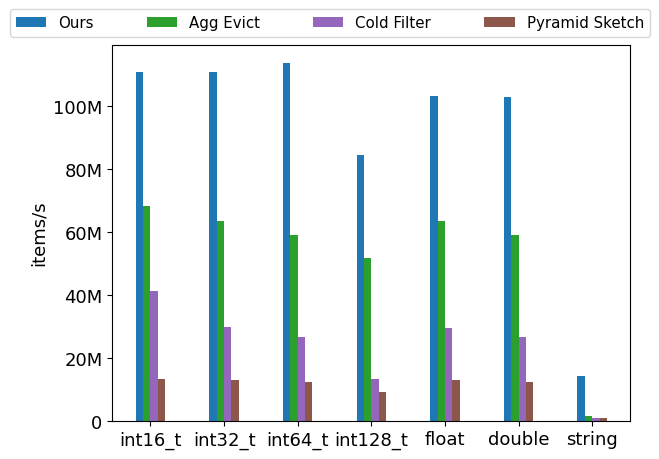

## SpaceSaving

,namespace,sketch,data_type,item_size,items_per_second,item_time_ns,slowdown_over_final
28,final,SpaceSaving,int16_t,2.00,"54,152,637.64",18.47,1.00
29,final,SpaceSaving,int32_t,4.00,"49,264,577.01",20.30,1.00
30,final,SpaceSaving,int64_t,8.00,"37,745,576.28",26.49,1.00
31,final,SpaceSaving,int128_t,16.00,"24,496,285.07",40.82,1.00
32,final,SpaceSaving,float,4.00,"44,082,704.13",22.68,1.00
33,final,SpaceSaving,double,8.00,"34,492,416.84",28.99,1.00
34,final,SpaceSaving,string,327.00,"7,291,169.34",137.15,1.00
35,agg_evict,SpaceSaving,int16_t,2.00,"5,924,121.64",168.80,9.14
36,agg_evict,SpaceSaving,int32_t,4.00,"7,882,876.15",126.86,6.25
37,agg_evict,SpaceSaving,int64_t,8.00,"6,414,235.76",155.90,5.88


cold_filter max slowdown over final: 5.26x
cold_filter max slowdown over final (no strings): 5.26x
agg_evict max slowdown over final: 9.14x
agg_evict max slowdown over final (no strings): 9.14x


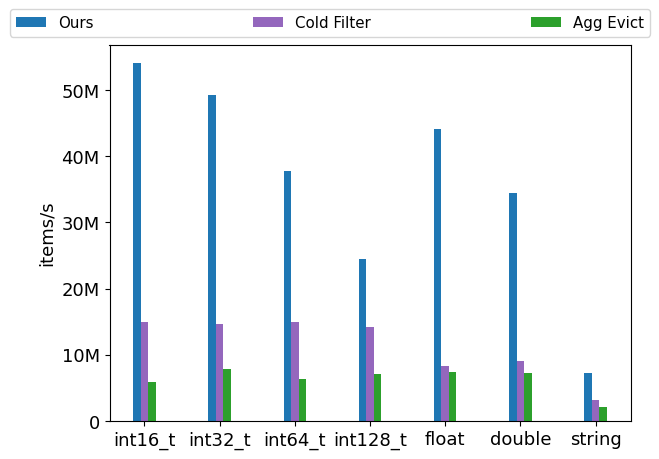

In [12]:
sketches = df_insert["sketch"].unique()

for sketch in sketches:
    for data_type in df_insert["data_type"].unique():
        mask = (df_insert["sketch"] == sketch) & (df_insert["data_type"] == data_type)

        baseline_final = df_insert.loc[
            mask & (df_insert["namespace"] == "final"), "items_per_second"
        ].iloc[0]

        df_insert.loc[mask, "slowdown_over_final"] = (
            baseline_final / df_insert.loc[mask, "items_per_second"]
        )

color_map = {"final": "C0", "naive": "C3", "datasketches": "C1"}

for sketch in sketches:
    display(Markdown(f"## {sketch}"))

    fig, ax = plt.subplots()

    mask = df_insert["sketch"] == sketch
    data = df_insert[mask]

    display(data)

    data_types = data["data_type"].unique()
    x = np.arange(len(data_types))
    width = 0.1

    namespaces = (
        data.groupby("namespace")["items_per_second"]
        .mean()
        .sort_values(ascending=False)
        .index
    )
    for i, namespace in enumerate(namespaces):
        if namespace != "final":
            max_slowdown = data[data["namespace"] == namespace][
                "slowdown_over_final"
            ].max()
            print(f"{namespace} max slowdown over final: {max_slowdown:.2f}x")
            max_slowdown = data[(data["namespace"] == namespace) & (data["data_type"] != "string")][
                "slowdown_over_final"
            ].max()
            print(f"{namespace} max slowdown over final (no strings): {max_slowdown:.2f}x")

        next_color_idx = 1

        mask_ns = data["namespace"] == namespace
        values = []
        for dt in data_types:
            dt_data = data[mask_ns & (data["data_type"] == dt)]["items_per_second"]
            if not dt_data.empty:
                values.append(dt_data.iloc[0])
            else:
                values.append(np.nan)

        color = color_map.get(namespace)
        if color is None:
            while f"C{next_color_idx}" in color_map.values():
                next_color_idx += 1
            color = f"C{next_color_idx}"
            color_map[namespace] = color
            next_color_idx += 1

        ax.bar(
            x + i * width - (len(namespaces) - 1) * width / 2,
            values,
            width,
            label=namespace,
            color=color,
        )

    ax.set_ylabel("items/s")
    ax.set_xticks(x)
    ax.set_xticklabels(data_types)
    ax.yaxis.set_major_formatter(si_formatter)

    handles, labels = ax.get_legend_handles_labels()
    new_labels = [NAMESPACE_MAP.get(label, label) for label in labels]

    ax.legend(
        handles,
        new_labels,
        bbox_to_anchor=(0, 0.9, 1, 0),
        loc="lower left",
        mode="expand",
        borderaxespad=0,
        ncol=4,
        fontsize="small",
        bbox_transform=fig.transFigure,
    )

    fig.tight_layout()
    display(fig)
    fig.savefig(
        f"figures/{sketch}_insert_final_vs_papers.pdf",
        bbox_inches="tight",
        pad_inches=0,
        dpi=300,
    )
    plt.close(fig)